# Foundation model against NDVI and PRODES

Does the change seen by Prithvi-EO-2.0 match the deforestation mapped by PRODES, and does it add anything to the NDVI change used by the alerts? This notebook compares the three at the scale of the model, patches of 480 m.

It reads only files written by the previous notebooks: the distance map from `03_foundation_model.ipynb`, the NDVI change map and the alerts from `01_detection.ipynb`, and the PRODES file in `data/`. It does not need PyTorch and runs in the main environment.

## 1. Settings

The patch geometry is the same as in the foundation model notebook: 23 × 23 patches of 480 m, each made of 48 × 48 pixels at 10 m. The PRODES years, the NDVI threshold and the "found" cut-off are the same as in the detection and validation notebooks.

In [1]:
%load_ext autoreload
%autoreload 2

import json
from datetime import date
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rioxarray
from scipy.stats import percentileofscore, spearmanr
from shapely.geometry import box

from utils import to_mask, polygon_coverage, patch_mean, auc_score

DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")
FIGURE_DIR = OUTPUT_DIR / "figures"

MODEL_NAME = "prithvi_eo_v2_300"
BLOCK = 3                               # 3 x 3 pixels at 10 m = 1 pixel at 30 m
PATCH = 16                              # model patch, in 30 m pixels
N_PATCHES = 23                          # patches per side covering the AOI
GRID_10M = N_PATCHES * PATCH * BLOCK    # 1104 pixels at 10 m
PATCH_PIXELS = PATCH * BLOCK            # 48 pixels at 10 m per patch side
PATCH_M = PATCH_PIXELS * 10             # 480 m

PRODES_PATH = DATA_DIR / "prodes_amazonia_legal_v20260717.gpkg"
YEARS_COMPARED = (2019, 2023)     # same PRODES years as the validation notebook
CHANGE_THRESHOLD = -0.25          # same NDVI drop as the detection notebook
FOUND_THRESHOLD = 0.5             # same "found" cut-off as the validation notebook
PRODES_PATCH_SHARE = 0.10         # a patch "contains a clearing" if PRODES covers at least 10% of it
MOSTLY_FOREST = 0.5               # a patch is "mostly forest" if under half of it was cleared before 2019

## 2. The two change maps

The Prithvi distance per patch, saved by the foundation model notebook, and the NDVI change at 10 m, averaged over the same patches.

In [2]:
prithvi_change = rioxarray.open_rasterio(OUTPUT_DIR / "prithvi_change.tif").squeeze("band", drop=True)
distance = prithvi_change.values

ndvi_change = rioxarray.open_rasterio(OUTPUT_DIR / "ndvi_change.tif").squeeze("band", drop=True)
ndvi_patch = patch_mean(ndvi_change.values, GRID_10M, PATCH_PIXELS)

print("distance grid:", distance.shape, "| NDVI per patch:", ndvi_patch.shape)

distance grid: (23, 23) | NDVI per patch: (23, 23)


## 3. Side by side

Comparing a 480 m patch with 10 m pixels would be unfair to the model, so the NDVI change is shown averaged over the same 23 × 23 patches.

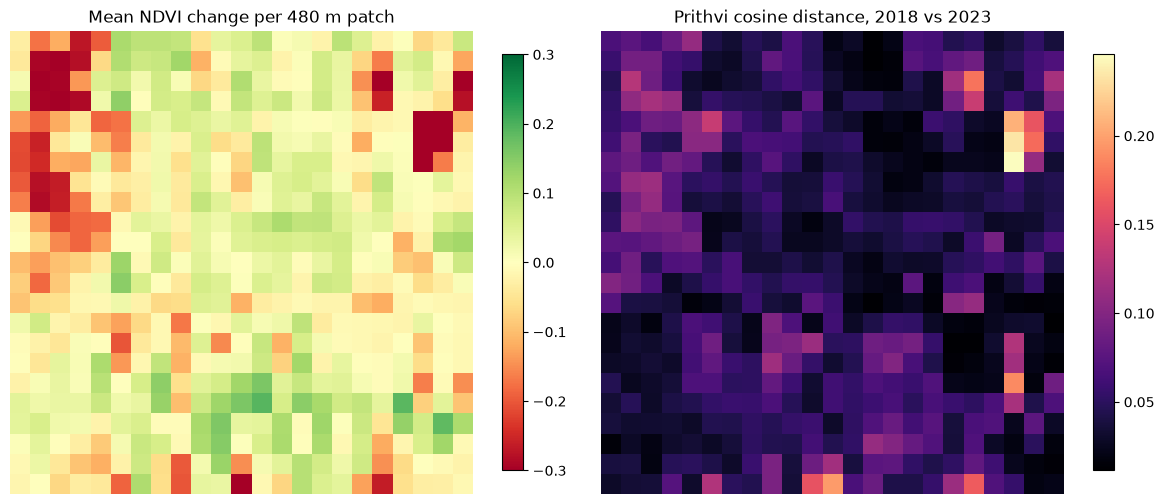

In [3]:
west, south, east, north = prithvi_change.rio.bounds()
extent = [west, east, south, north]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
im0 = axes[0].imshow(ndvi_patch, cmap="RdYlGn", vmin=-0.3, vmax=0.3, extent=extent)
axes[0].set_title("Mean NDVI change per 480 m patch")
fig.colorbar(im0, ax=axes[0], shrink=0.8)
im1 = axes[1].imshow(distance, cmap="magma", extent=extent)
axes[1].set_title("Prithvi cosine distance, 2018 vs 2023")
fig.colorbar(im1, ax=axes[1], shrink=0.8)
for ax in axes:
    ax.set_axis_off()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "prithvi_vs_ndvi_patches.png", dpi=150)
plt.show()

## 4. Change in any direction

The cosine distance has no sign: it says how differently the model describes a patch in the two periods, not whether the patch lost or gained vegetation. The mean NDVI change of a patch, on the other hand, lets losses and gains cancel out. Comparing the distance with several summaries of the NDVI change shows which kind of change the model follows.

Spearman correlation compares rankings, so it does not assume a straight-line relationship. Neighbouring patches are not independent, so no p-value is reported: it would look far more certain than it is.

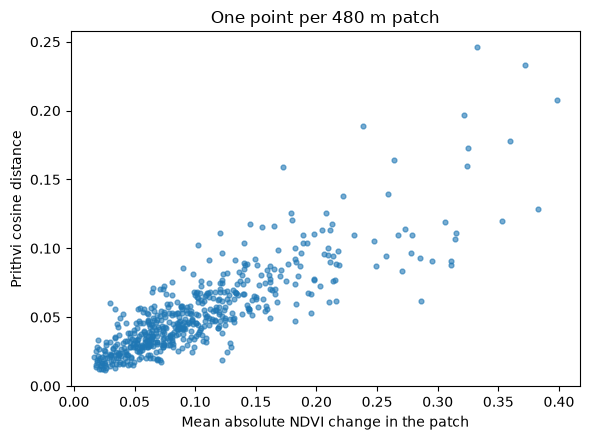

mean NDVI change (signed)        -0.34
mean absolute NDVI change         0.84
share of pixels losing > 0.25     0.70
share of pixels gaining > 0.25    0.18
Name: Spearman with Prithvi distance, dtype: float64

In [4]:
change_measures = {
    "mean NDVI change (signed)": ndvi_patch,
    "mean absolute NDVI change": patch_mean(np.abs(ndvi_change.values), GRID_10M, PATCH_PIXELS),
    "share of pixels losing > 0.25": patch_mean(ndvi_change.values < CHANGE_THRESHOLD, GRID_10M, PATCH_PIXELS),
    "share of pixels gaining > 0.25": patch_mean(ndvi_change.values > -CHANGE_THRESHOLD, GRID_10M, PATCH_PIXELS),
}

correlations = pd.Series(
    {name: spearmanr(values.ravel(), distance.ravel())[0] for name, values in change_measures.items()},
    name="Spearman with Prithvi distance",
)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(change_measures["mean absolute NDVI change"].ravel(), distance.ravel(), s=12, alpha=0.6)
ax.set_xlabel("Mean absolute NDVI change in the patch")
ax.set_ylabel("Prithvi cosine distance")
ax.set_title("One point per 480 m patch")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "prithvi_vs_ndvi_scatter.png", dpi=150)
plt.show()

correlations.round(2)

## 5. PRODES on the patch grid

The same PRODES layers as in the validation notebook are drawn on the 10 m grid and averaged over each patch. This gives, for every 480 m patch, the share covered by clearings mapped in 2019 to 2023, the share PRODES already considered cleared or not forest by 2018, and the share covered by the alerts.

A patch counts as containing a clearing when PRODES covers at least 10% of it, about 2.3 ha. A patch counts as mostly forest when less than half of it had been cleared before 2019: there PRODES can still report new deforestation over most of the ground.

In [5]:
read_bbox = ndvi_change.rio.transform_bounds("EPSG:4674")
yearly = gpd.read_file(PRODES_PATH, layer="yearly_deforestation", bbox=read_bbox)
prodes_recent = yearly[yearly["year"].between(*YEARS_COMPARED)]
prodes_earlier = yearly[yearly["year"] < YEARS_COMPARED[0]]
accumulated = gpd.read_file(PRODES_PATH, layer="accumulated_deforestation_2007", bbox=read_bbox)
no_forest = gpd.read_file(PRODES_PATH, layer="no_forest", bbox=read_bbox)
hydrography = gpd.read_file(PRODES_PATH, layer="hydrography", bbox=read_bbox)
alerts = gpd.read_file(OUTPUT_DIR / "deforestation_alerts.geojson")

not_forest_2018 = (to_mask(accumulated, ndvi_change) | to_mask(prodes_earlier, ndvi_change)
                   | to_mask(no_forest, ndvi_change) | to_mask(hydrography, ndvi_change))

patches = pd.DataFrame({
    "prithvi_distance": distance.ravel(),
    "mean_abs_ndvi_change": change_measures["mean absolute NDVI change"].ravel(),
    "ndvi_loss_share": change_measures["share of pixels losing > 0.25"].ravel(),
    "alert_share": patch_mean(to_mask(alerts, ndvi_change), GRID_10M, PATCH_PIXELS).ravel(),
    "prodes_share": patch_mean(to_mask(prodes_recent, ndvi_change), GRID_10M, PATCH_PIXELS).ravel(),
    "not_forest_2018_share": patch_mean(not_forest_2018, GRID_10M, PATCH_PIXELS).ravel(),
})
patches["has_prodes"] = patches["prodes_share"] >= PRODES_PATCH_SHARE
patches["mostly_forest"] = patches["not_forest_2018_share"] < MOSTLY_FOREST

print(len(patches), "patches,", int(patches["has_prodes"].sum()), "with a PRODES clearing,",
      int(patches["mostly_forest"].sum()), "mostly forest in 2018")
patches.describe().round(3).T[["mean", "min", "max"]]

529 patches, 44 with a PRODES clearing, 104 mostly forest in 2018


,mean,min,max
prithvi_distance,0.053,0.011,0.246
mean_abs_ndvi_change,0.104,0.016,0.398
ndvi_loss_share,0.093,0.000,0.954
alert_share,0.086,0.000,0.954
prodes_share,0.034,0.000,0.950
not_forest_2018_share,0.775,0.000,1.000


## 7. Which score separates the PRODES patches best

For each score, the AUC: the probability that a patch containing a PRODES clearing scores higher than a patch without one. 0.5 is chance, 1 a perfect separation. Only the ranking matters, so scores on very different scales can be compared.

Four scores, all at 480 m: the Prithvi distance, the mean absolute NDVI change, the share of pixels where NDVI dropped by more than 0.25, and the share covered by the alerts. They are computed on all patches, and again on the patches that were mostly forest in 2018, where PRODES can still see new clearings.

With a few dozen PRODES patches the differences between scores are uncertain: a gap of a few hundredths should not be read as one score being better.

In [6]:
scores = {
    "Prithvi distance": "prithvi_distance",
    "mean absolute NDVI change": "mean_abs_ndvi_change",
    "share of NDVI loss pixels": "ndvi_loss_share",
    "share covered by alerts": "alert_share",
}

forest = patches[patches["mostly_forest"]]
separation = pd.DataFrame({
    "all patches": {label: auc_score(patches[col], patches["has_prodes"]) for label, col in scores.items()},
    "mostly forest in 2018": {label: auc_score(forest[col], forest["has_prodes"]) for label, col in scores.items()},
})

print("PRODES patches:", int(patches["has_prodes"].sum()), "of", len(patches),
      "| among mostly forest:", int(forest["has_prodes"].sum()), "of", len(forest))
separation.round(2)

PRODES patches: 44 of 529 | among mostly forest: 23 of 104


,all patches,mostly forest in 2018
Prithvi distance,0.87,0.97
mean absolute NDVI change,0.80,0.92
share of NDVI loss pixels,0.87,0.92
share covered by alerts,0.85,0.90


## 8. The clearings the alerts missed

In the validation notebook, two PRODES clearings larger than a few hectares were missed entirely by the alerts, and their mean NDVI change was close to zero: the vegetation had grown back by 2023. A two-date NDVI difference cannot see them. The question here is whether the model still describes those patches as changed.

For each PRODES clearing of at least 5 ha that the alerts did not find, the table gives the patch its centroid falls in, the Prithvi distance of that patch, its percentile among all 529 patches, and the share of NDVI loss pixels in the same patch. A high percentile with almost no NDVI loss would mean the model sees something the index does not.

In [7]:
patch_footprint = gpd.GeoDataFrame(geometry=[box(*prithvi_change.rio.bounds())], crs=prithvi_change.rio.crs)
prodes_utm = gpd.clip(prodes_recent.to_crs(prithvi_change.rio.crs), patch_footprint).reset_index(drop=True)
prodes_utm["area_ha"] = prodes_utm.area / 10_000
prodes_utm["coverage"] = polygon_coverage(prodes_utm, alerts.to_crs(prodes_utm.crs))

not_found = prodes_utm[(prodes_utm["coverage"] < FOUND_THRESHOLD) & (prodes_utm["area_ha"] >= 5)].copy()

transform = prithvi_change.rio.transform()
centroids = not_found.geometry.centroid
not_found["patch_row"] = ((transform.f - centroids.y) // PATCH_M).astype(int).clip(0, N_PATCHES - 1)
not_found["patch_col"] = ((centroids.x - transform.c) // PATCH_M).astype(int).clip(0, N_PATCHES - 1)

rows, cols = not_found["patch_row"].to_numpy(), not_found["patch_col"].to_numpy()
not_found["prithvi_distance"] = distance[rows, cols]
not_found["distance_percentile"] = [percentileofscore(distance.ravel(), d) for d in not_found["prithvi_distance"]]
not_found["patch_ndvi_loss_share"] = change_measures["share of pixels losing > 0.25"][rows, cols]

not_found[["year", "area_ha", "coverage", "prithvi_distance",
           "distance_percentile", "patch_ndvi_loss_share"]].sort_values("coverage").round(3)

C:\Users\angel\anaconda3\envs\deforestation-gfm\Lib\site-packages\geopandas\tools\overlay.py:386: UserWarning: `keep_geom_type=True` in overlay resulted in 3 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  result = _collection_extract(result, geom_type, keep_geom_type_warning)


,year,area_ha,coverage,prithvi_distance,distance_percentile,patch_ndvi_loss_share
5,2020,6.411,0.000,0.029,20.794,0.002
10,2021,11.146,0.000,0.071,79.773,0.093
13,2021,12.454,0.002,0.061,69.187,0.080
6,2019,6.294,0.009,0.058,66.730,0.019
21,2022,37.904,0.060,0.050,55.198,0.013
27,2023,15.162,0.147,0.069,78.072,0.142
23,2019,19.050,0.183,0.104,93.384,0.288
7,2022,14.504,0.251,0.068,75.992,0.226
28,2020,8.757,0.312,0.097,92.060,0.743
16,2021,8.994,0.471,0.076,82.231,0.029


## 9. Saving the results

The main numbers of this comparison are written to `outputs/prithvi_metrics.json`, next to the validation metrics, so the assistant can report what the foundation model adds, and what it does not, without running the model again.

In [8]:
prithvi_metrics = {
    "generated_on": date.today().isoformat(),
    "model": MODEL_NAME,
    "patch_size_m": PATCH_M,
    "n_patches": int(distance.size),
    "distance": {"min": round(float(distance.min()), 4),
                 "median": round(float(np.median(distance)), 4),
                 "max": round(float(distance.max()), 4)},
    "spearman_with_ndvi": {k: round(float(v), 3) for k, v in correlations.items()},
    "prodes_patch_share_threshold": PRODES_PATCH_SHARE,
    "n_patches_with_prodes": int(patches["has_prodes"].sum()),
    "auc_all_patches": {k: round(float(v), 3) for k, v in separation["all patches"].items()},
    "auc_mostly_forest": {k: round(float(v), 3) for k, v in separation["mostly forest in 2018"].items()},
    "missed_clearings": not_found[["year", "area_ha", "coverage", "prithvi_distance",
                                   "distance_percentile"]].round(3).to_dict(orient="records"),
}

with open(OUTPUT_DIR / "prithvi_metrics.json", "w") as f:
    json.dump(prithvi_metrics, f, indent=2, default=int)

print(json.dumps(prithvi_metrics, indent=2, default=int))

{
  "generated_on": "2026-10-12",
  "model": "prithvi_eo_v2_300",
  "patch_size_m": 480,
  "n_patches": 529,
  "distance": {
    "min": 0.0114,
    "median": 0.0466,
    "max": 0.2459
  },
  "spearman_with_ndvi": {
    "mean NDVI change (signed)": -0.342,
    "mean absolute NDVI change": 0.835,
    "share of pixels losing > 0.25": 0.704,
    "share of pixels gaining > 0.25": 0.176
  },
  "prodes_patch_share_threshold": 0.1,
  "n_patches_with_prodes": 44,
  "auc_all_patches": {
    "Prithvi distance": 0.869,
    "mean absolute NDVI change": 0.803,
    "share of NDVI loss pixels": 0.868,
    "share covered by alerts": 0.847
  },
  "auc_mostly_forest": {
    "Prithvi distance": 0.967,
    "mean absolute NDVI change": 0.922,
    "share of NDVI loss pixels": 0.922,
    "share covered by alerts": 0.898
  },
  "missed_clearings": [
    {
      "year": 2020,
      "area_ha": 6.411,
      "coverage": 0.0,
      "prithvi_distance": 0.028999999165534973,
      "distance_percentile": 20.794
    },